In [1]:
!pip install arch yfinance --upgrade -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 44.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 13.1 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
base = "/content/drive/MyDrive/volatility-risk-analysis"
os.makedirs(f"{base}/data", exist_ok=True)
os.makedirs(f"{base}/outputs", exist_ok=True)
print(os.listdir(base))

['data', 'outputs']


In [4]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import arch
print("arch version:", arch.__version__)
print("all good")

arch version: 8.0.0
all good


In [10]:
ticker = "GLD"   # change to "GLD" later for gold
price = yf.download(ticker, start="2005-01-01", auto_adjust=True)["Close"].squeeze()

print(price.shape)
print(price.head())
print(price.tail())
print("missing:", price.isna().sum())

[*********************100%***********************]  1 of 1 completed

(5482,)
Date
2005-01-03    43.020000
2005-01-04    42.740002
2005-01-05    42.669998
2005-01-06    42.150002
2005-01-07    41.840000
Name: GLD, dtype: float64
Date
2026-10-12    382.149994
2026-10-13    381.670013
2026-10-14    375.989990
2026-10-15    382.709991
2026-10-16    382.010010
Name: GLD, dtype: float64
missing: 0


In [11]:
returns = np.log(price).diff().dropna()
print(returns.head())

Date
2005-01-04   -0.006530
2005-01-05   -0.001639
2005-01-06   -0.012261
2005-01-07   -0.007382
2005-01-10    0.002626
Name: GLD, dtype: float64


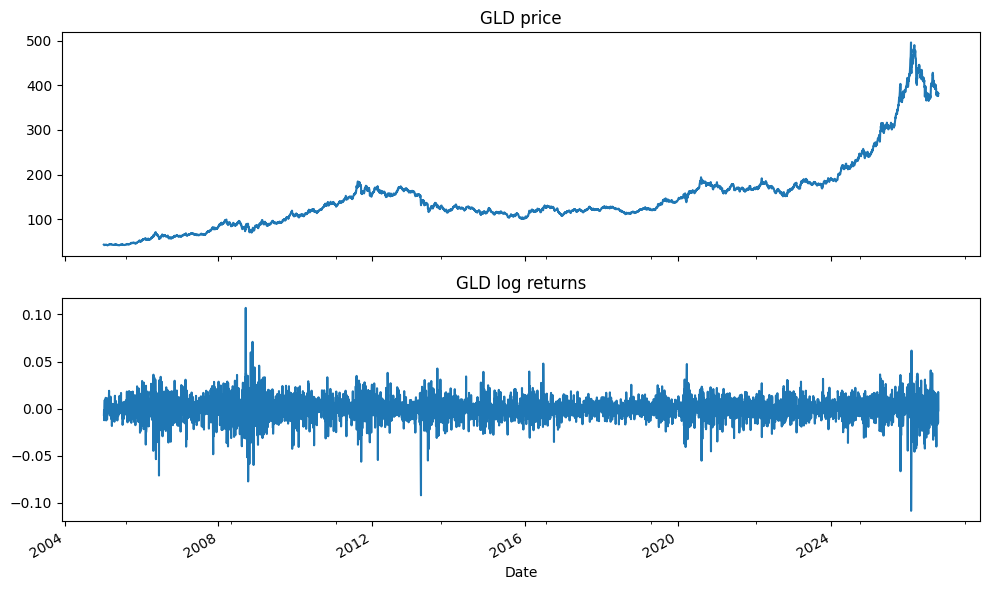

In [12]:
base = "/content/drive/MyDrive/volatility-risk-analysis"

fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
price.plot(ax=ax[0], title=f"{ticker} price")
returns.plot(ax=ax[1], title=f"{ticker} log returns")
plt.tight_layout()
plt.savefig(f"{base}/outputs/price_vs_returns_{ticker}.png")
plt.show()

In [13]:
print(returns.describe())
print("skew:", returns.skew())
print("kurtosis:", returns.kurtosis())

returns.to_csv(f"{base}/data/{ticker}_returns.csv")

count    5481.000000
mean        0.000398
std         0.011540
min        -0.108412
25%        -0.005165
50%         0.000590
75%         0.006390
max         0.106974
Name: GLD, dtype: float64
skew: -0.45094751059401705
kurtosis: 6.576909445234254


In [14]:
from statsmodels.tsa.stattools import adfuller

def adf(series, name):
    stat, p = adfuller(series.dropna())[:2]
    verdict = "stationary" if p < 0.05 else "NOT stationary"
    print(f"{name}: ADF stat = {stat:.3f}, p-value = {p:.4f} -> {verdict}")

adf(price, "price")
adf(returns, "returns")

/tmp/ipykernel_3341/3493310322.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(series.dropna())[:2]


price: ADF stat = 0.641, p-value = 0.9886 -> NOT stationary
returns: ADF stat = -75.178, p-value = 0.0000 -> stationary


/tmp/ipykernel_3341/3493310322.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p = adfuller(series.dropna())[:2]


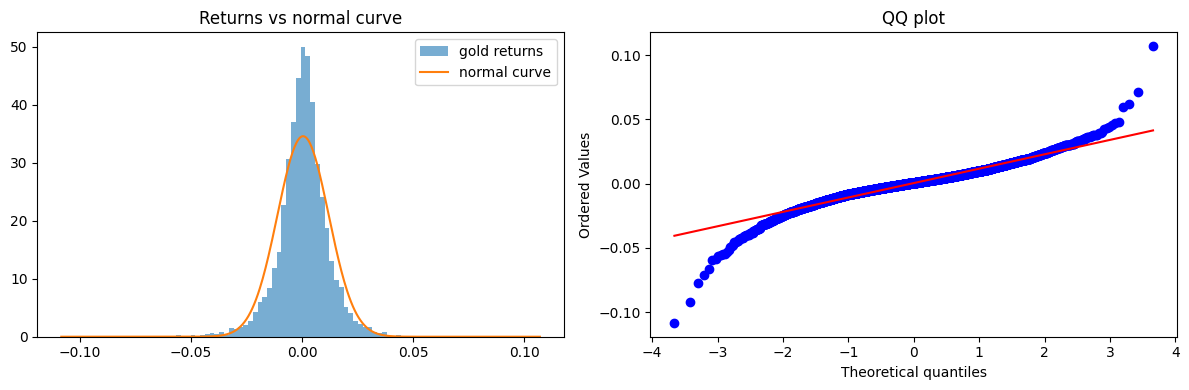

In [15]:
from scipy import stats

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(returns, bins=100, density=True, alpha=0.6, label="gold returns")
x = np.linspace(returns.min(), returns.max(), 500)
ax[0].plot(x, stats.norm.pdf(x, returns.mean(), returns.std()), label="normal curve")
ax[0].set_title("Returns vs normal curve")
ax[0].legend()

stats.probplot(returns, dist="norm", plot=ax[1])
ax[1].set_title("QQ plot")

plt.tight_layout()
plt.savefig(f"{base}/outputs/hist_qq_{ticker}.png")
plt.show()

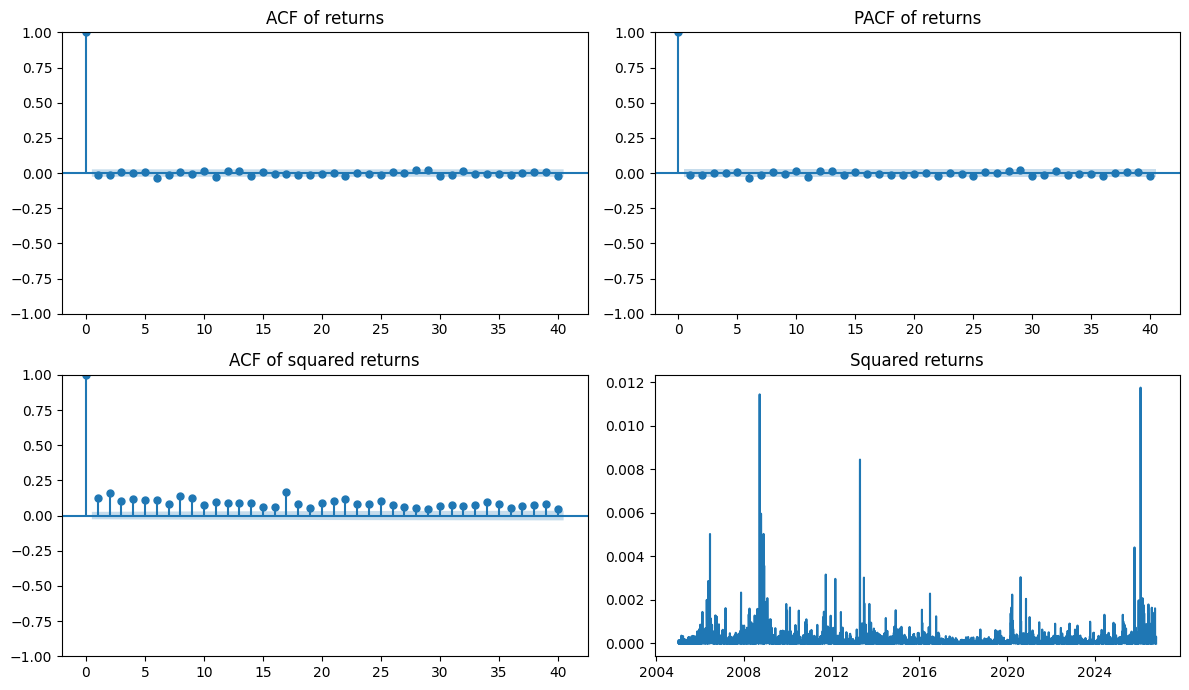

In [16]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, ax = plt.subplots(2, 2, figsize=(12, 7))

plot_acf(returns, lags=40, ax=ax[0, 0], title="ACF of returns")
plot_pacf(returns, lags=40, ax=ax[0, 1], title="PACF of returns", method="ywm")
plot_acf(returns**2, lags=40, ax=ax[1, 0], title="ACF of squared returns")
ax[1, 1].plot(returns**2)
ax[1, 1].set_title("Squared returns")

plt.tight_layout()
plt.savefig(f"{base}/outputs/acf_pacf_{ticker}.png")
plt.show()

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox

lb_ret = acorr_ljungbox(returns, lags=[10, 20], return_df=True)
lb_sq = acorr_ljungbox(returns**2, lags=[10, 20], return_df=True)

print("Ljung-Box on returns:")
print(lb_ret)
print("\nLjung-Box on squared returns:")
print(lb_sq)

Ljung-Box on returns:
      lb_stat  lb_pvalue
10  13.770974   0.183697
20  23.523722   0.263816

Ljung-Box on squared returns:
        lb_stat      lb_pvalue
10   750.424363  9.310194e-155
20  1224.530858  4.222969e-247
